# Ablation studies
Wine Quality dataset (red and white wines)

The best model of notebooks 03 and 04 is a random forest. Here we change one decision of the
pipeline at a time and repeat the same nested cross-validation, to see how much each decision
matters:

1. **Duplicates**: keeping the 1,177 repeated rows instead of removing them.
2. **Wine type**: removing the `is_red` input.
3. **One model per type**: training separate models for red and white wines.
4. **Log transform**: applying `log1p` to the skewed variables in the linear and KNN models.

The reference results are the out-of-fold predictions saved by notebooks 03 and 04.

## 0. Libraries and plot style

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Colours for the plots
PLUM, PURPLE, LILAC = "#4A1942", "#7D3C98", "#C39BD3"
PINK, ROSE = "#E0719E", "#F5B7C8"
ORANGE, APRICOT = "#E8743B", "#F6A96B"
CREAM, INK = "#FDF1EC", "#3B2A3F"

PALETTE = [PURPLE, PINK, ORANGE, LILAC, APRICOT, PLUM, ROSE]
CLASS_ORDER = ["Low", "Medium", "High"]
CLASS_COLORS = {"Low": PURPLE, "Medium": PINK, "High": ORANGE}
TYPE_COLORS = {"red": PLUM, "white": APRICOT}
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#FFFFFF", ROSE, PINK, PURPLE, PLUM])
CMAP_DIV = LinearSegmentedColormap.from_list("div", [PURPLE, LILAC, "#FFFFFF", APRICOT, ORANGE])

sns.set_theme(style="white", palette=PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#CBB8CF", "axes.labelcolor": INK, "axes.titlecolor": PLUM,
    "axes.titleweight": "semibold", "axes.titlesize": 12, "axes.grid": True,
    "grid.color": "#F1E4EC", "xtick.color": INK, "ytick.color": INK,
    "legend.frameon": False, "text.color": INK,
})

FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print("Figure saved ->", FIG_DIR / name)

In [2]:
from sklearn.model_selection import KFold, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, f1_score

SEED = 42
RES_DIR = Path("../results")

FEATURES = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar",
            "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
            "pH", "sulphates", "alcohol"]
SKEWED = ["residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide",
          "sulphates", "volatile acidity", "fixed acidity"]

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    values = [metric(y_true[idx], y_pred[idx])
              for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(values, [2.5, 97.5])

def paired_bootstrap(y_true, pred_a, pred_b, metric, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        diffs[b] = metric(y_true[idx], pred_a[idx]) - metric(y_true[idx], pred_b[idx])
    return np.percentile(diffs, [2.5, 97.5])

## 1. Data with and without duplicates

In [3]:
raw = Path("../data/raw")
red = pd.read_csv(raw / "winequality-red.csv", sep=";").assign(wine_type="red")
white = pd.read_csv(raw / "winequality-white.csv", sep=";").assign(wine_type="white")
wine_full = pd.concat([red, white], ignore_index=True)
wine = pd.read_csv("../data/wine_clean.csv")
for df in (wine_full, wine):
    df["is_red"] = (df["wine_type"] == "red").astype(int)
    df["label"] = pd.cut(df["quality"], bins=[0, 5, 6, 10], labels=[0, 1, 2]).astype(int)
print("with duplicates:", wine_full.shape, "  without duplicates:", wine.shape)

with duplicates: (6497, 15)   without duplicates: (5320, 16)


## 2. Nested cross-validation function

Same procedure as in notebooks 03 and 04: 5 outer folds, 3 inner folds, `GridSearchCV` inside,
seed 42. `task` is either `"reg"` (RMSE) or `"clf"` (macro F1, stratified folds).

In [4]:
RF_REG = (Pipeline([("model", RandomForestRegressor(n_estimators=300, random_state=SEED))]),
          {"model__max_features": ["sqrt", 0.5], "model__min_samples_leaf": [1, 5]})
RF_CLF = (Pipeline([("model", RandomForestClassifier(n_estimators=300, random_state=SEED))]),
          {"model__max_features": ["sqrt", 0.5], "model__min_samples_leaf": [1, 5],
           "model__class_weight": [None, "balanced"]})

def nested_cv(X, y, pipeline, grid, task):
    if task == "reg":
        outer_cv = KFold(5, shuffle=True, random_state=SEED)
        inner_cv = KFold(3, shuffle=True, random_state=SEED)
        scoring, metric = "neg_root_mean_squared_error", rmse
    else:
        outer_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
        inner_cv = StratifiedKFold(3, shuffle=True, random_state=SEED)
        scoring, metric = "f1_macro", macro_f1
    oof = np.zeros(len(y))
    scores, folds = [], []
    for train_idx, test_idx in outer_cv.split(X, y):
        search = GridSearchCV(pipeline, grid, scoring=scoring, cv=inner_cv, n_jobs=-1)
        search.fit(X[train_idx], y[train_idx])
        oof[test_idx] = search.predict(X[test_idx])
        scores.append(metric(y[test_idx], oof[test_idx]))
        folds.append((train_idx, test_idx))
    return oof, np.array(scores), folds

## 3. Reference results (notebooks 03 and 04)

In [5]:
ref_reg = pd.read_csv(RES_DIR / "regression_oof_predictions.csv")
ref_clf = pd.read_csv(RES_DIR / "classification_oof_predictions.csv")
y_reg, y_clf = wine["quality"].to_numpy(), wine["label"].to_numpy()
assert (ref_reg["y_true"].to_numpy() == y_reg).all() and (ref_clf["y_true"].to_numpy() == y_clf).all()
reg_folds = pd.read_csv(RES_DIR / "regression_nested_folds.csv")
clf_folds = pd.read_csv(RES_DIR / "classification_nested_folds.csv")

rows = []
def add_row(task, experiment, model, y, oof, fold_scores, ref_oof=None):
    metric = rmse if task == "reg" else macro_f1
    lo, hi = bootstrap_ci(y, oof, metric)
    row = {"task": "Regression (RMSE)" if task == "reg" else "Classification (macro F1)",
           "experiment": experiment, "model": model, "n wines": len(y),
           "mean": np.mean(fold_scores), "std": np.std(fold_scores, ddof=1),
           "CI low": lo, "CI high": hi, "diff CI low": np.nan, "diff CI high": np.nan}
    if ref_oof is not None:
        row["diff CI low"], row["diff CI high"] = paired_bootstrap(y, oof, ref_oof, metric)
    rows.append(row)
    print(f"{row['task']:26s} {experiment:38s} {model:20s} {row['mean']:.3f} [{lo:.3f}, {hi:.3f}]")

add_row("reg", "Reference", "Random forest", y_reg, ref_reg["Random forest"].to_numpy(),
        reg_folds.query("model == 'Random forest'")["RMSE"])
add_row("clf", "Reference", "Random forest", y_clf, ref_clf["Random forest"].to_numpy().astype(int),
        clf_folds.query("model == 'Random forest'")["Macro F1"])

Regression (RMSE)          Reference                              Random forest        0.680 [0.663, 0.696]


Classification (macro F1)  Reference                              Random forest        0.604 [0.592, 0.619]


## 4. Ablation 1: keeping the duplicated rows

We also measure how many wines of each outer test fold have an identical copy (same
measurements, type and quality) in the training folds.

In [6]:
cols = FEATURES + ["is_red"]
X_full = wine_full[cols].to_numpy()
keys = pd.util.hash_pandas_object(wine_full[cols + ["quality"]], index=False).to_numpy()
for task, target, (pipe, grid) in [("reg", "quality", RF_REG), ("clf", "label", RF_CLF)]:
    y_full = wine_full[target].to_numpy()
    oof, scores, folds = nested_cv(X_full, y_full, pipe, grid, task)
    if task == "clf":
        oof = oof.astype(int)
    twins = [np.isin(keys[te], keys[tr]).mean() for tr, te in folds]
    print(f"  share of test wines with a twin in training: {np.mean(twins):.3f} (folds: {np.round(twins, 3)})")
    add_row(task, "With duplicates (6,497 rows)", "Random forest", y_full, oof, scores)
    rows[-1]["twin share"] = np.mean(twins)

  share of test wines with a twin in training: 0.276 (folds: [0.276 0.268 0.286 0.266 0.283])
Regression (RMSE)          With duplicates (6,497 rows)           Random forest        0.596 [0.580, 0.612]


  share of test wines with a twin in training: 0.279 (folds: [0.258 0.292 0.276 0.279 0.292])


Classification (macro F1)  With duplicates (6,497 rows)           Random forest        0.718 [0.705, 0.730]


## 5. Ablation 2: without the `is_red` input

In [7]:
X_nored = wine[FEATURES].to_numpy()
for task, y, (pipe, grid), ref in [("reg", y_reg, RF_REG, ref_reg), ("clf", y_clf, RF_CLF, ref_clf)]:
    oof, scores, _ = nested_cv(X_nored, y, pipe, grid, task)
    if task == "clf":
        oof = oof.astype(int)
    add_row(task, "Without is_red", "Random forest", y, oof, scores,
            ref_oof=ref["Random forest"].to_numpy().astype(oof.dtype))

Regression (RMSE)          Without is_red                         Random forest        0.680 [0.663, 0.695]


Classification (macro F1)  Without is_red                         Random forest        0.599 [0.587, 0.614]


## 6. Ablation 3: one model per wine type

A separate nested cross-validation is run for red and for white wines. The out-of-fold
predictions of both are put together, so the metric is computed on the same 5,320 wines as the
reference. Red folds are smaller than white folds, so the mean of the 10 fold scores is not
comparable with the other rows. The value saved in the table is the metric computed on
all 5,320 out-of-fold predictions, and the standard deviation is that of the 10 folds.

In [8]:
for task, y, (pipe, grid), ref in [("reg", y_reg, RF_REG, ref_reg), ("clf", y_clf, RF_CLF, ref_clf)]:
    oof = np.zeros(len(y))
    all_scores = []
    for t in ["red", "white"]:
        m = (wine["wine_type"] == t).to_numpy()
        oof_t, scores_t, _ = nested_cv(wine.loc[m, FEATURES].to_numpy(), y[m], pipe, grid, task)
        oof[m] = oof_t
        all_scores += list(scores_t)
        print(f"  {t}: {np.mean(scores_t):.3f}")
    if task == "clf":
        oof = oof.astype(int)
    add_row(task, "One model per wine type", "Random forest", y, oof, all_scores,
            ref_oof=ref["Random forest"].to_numpy().astype(oof.dtype))
    metric = rmse if task == "reg" else macro_f1
    rows[-1]["mean"] = metric(y, oof)
    print(f"  metric on the 5,320 out-of-fold predictions: {rows[-1]['mean']:.3f}")

  red: 0.640


  white: 0.696


Regression (RMSE)          One model per wine type                Random forest        0.668 [0.667, 0.699]
  metric on the 5,320 out-of-fold predictions: 0.683


  red: 0.605


  white: 0.596


Classification (macro F1)  One model per wine type                Random forest        0.600 [0.590, 0.617]
  metric on the 5,320 out-of-fold predictions: 0.603


## 7. Ablation 4: log transform of the skewed variables

Linear models and KNN are sensitive to long right tails. We apply `log1p` to the skewed
variables before the scaler, inside the Pipeline.

In [9]:
cols = FEATURES + ["is_red"]
skew_idx = [cols.index(c) for c in SKEWED]
X = wine[cols].to_numpy()

def with_log(estimator):
    log = ColumnTransformer([("log", FunctionTransformer(np.log1p), skew_idx)], remainder="passthrough")
    return Pipeline([("log", log), ("scaler", StandardScaler()), ("model", estimator)])

LOG_MODELS = [
    ("reg", "Linear regression", with_log(LinearRegression()), {}, y_reg, ref_reg),
    ("reg", "KNN", with_log(KNeighborsRegressor()),
     {"model__n_neighbors": [10, 25, 50], "model__weights": ["uniform", "distance"]}, y_reg, ref_reg),
    ("clf", "Logistic regression", with_log(LogisticRegression(max_iter=2000)),
     {"model__C": [0.01, 0.1, 1, 10]}, y_clf, ref_clf),
    ("clf", "KNN", with_log(KNeighborsClassifier()),
     {"model__n_neighbors": [10, 25, 50], "model__weights": ["uniform", "distance"]}, y_clf, ref_clf),
]
for task, name, pipe, grid, y, ref in LOG_MODELS:
    folds = reg_folds if task == "reg" else clf_folds
    col = "RMSE" if task == "reg" else "Macro F1"
    ref_oof = ref[name].to_numpy()
    if task == "clf":
        ref_oof = ref_oof.astype(int)
    add_row(task, "Reference", name, y, ref_oof, folds.query("model == @name")[col])
    oof, scores, _ = nested_cv(X, y, pipe, grid or {"model__fit_intercept": [True]}, task)
    if task == "clf":
        oof = oof.astype(int)
    add_row(task, "log1p of skewed variables", name, y, oof, scores, ref_oof=ref_oof)

Regression (RMSE)          Reference                              Linear regression    0.733 [0.716, 0.749]


Regression (RMSE)          log1p of skewed variables              Linear regression    0.727 [0.709, 0.745]
Regression (RMSE)          Reference                              KNN                  0.704 [0.688, 0.720]


Regression (RMSE)          log1p of skewed variables              KNN                  0.700 [0.684, 0.716]


Classification (macro F1)  Reference                              Logistic regression  0.557 [0.543, 0.572]


Classification (macro F1)  log1p of skewed variables              Logistic regression  0.559 [0.545, 0.574]


Classification (macro F1)  Reference                              KNN                  0.579 [0.566, 0.594]


Classification (macro F1)  log1p of skewed variables              KNN                  0.580 [0.565, 0.594]


## 8. Summary table and figure

,task,experiment,model,n wines,mean,std,CI low,CI high,diff CI low,diff CI high,twin share
0,Regression (RMSE),Reference,Random forest,5320,0.680,0.014,0.663,0.696,NaN,NaN,NaN
1,Classification (macro F1),Reference,Random forest,5320,0.604,0.012,0.592,0.619,NaN,NaN,NaN
2,Regression (RMSE),"With duplicates (6,497 rows)",Random forest,6497,0.596,0.006,0.580,0.612,NaN,NaN,0.276
3,Classification (macro F1),"With duplicates (6,497 rows)",Random forest,6497,0.718,0.017,0.705,0.730,NaN,NaN,0.279
4,Regression (RMSE),Without is_red,Random forest,5320,0.680,0.015,0.663,0.695,-0.002,0.002,NaN
5,Classification (macro F1),Without is_red,Random forest,5320,0.599,0.006,0.587,0.614,-0.013,0.003,NaN
6,Regression (RMSE),One model per wine type,Random forest,5320,0.683,0.036,0.667,0.699,-0.001,0.006,NaN
7,Classification (macro F1),One model per wine type,Random forest,5320,0.603,0.027,0.590,0.617,-0.013,0.008,NaN
8,Regression (RMSE),Reference,Linear regression,5320,0.733,0.016,0.716,0.749,NaN,NaN,NaN
9,Regression (RMSE),log1p of skewed variables,Linear regression,5320,0.727,0.015,0.709,0.745,-0.010,-0.001,NaN


Figure saved -> ../results/figures/abl_ablation_results.png


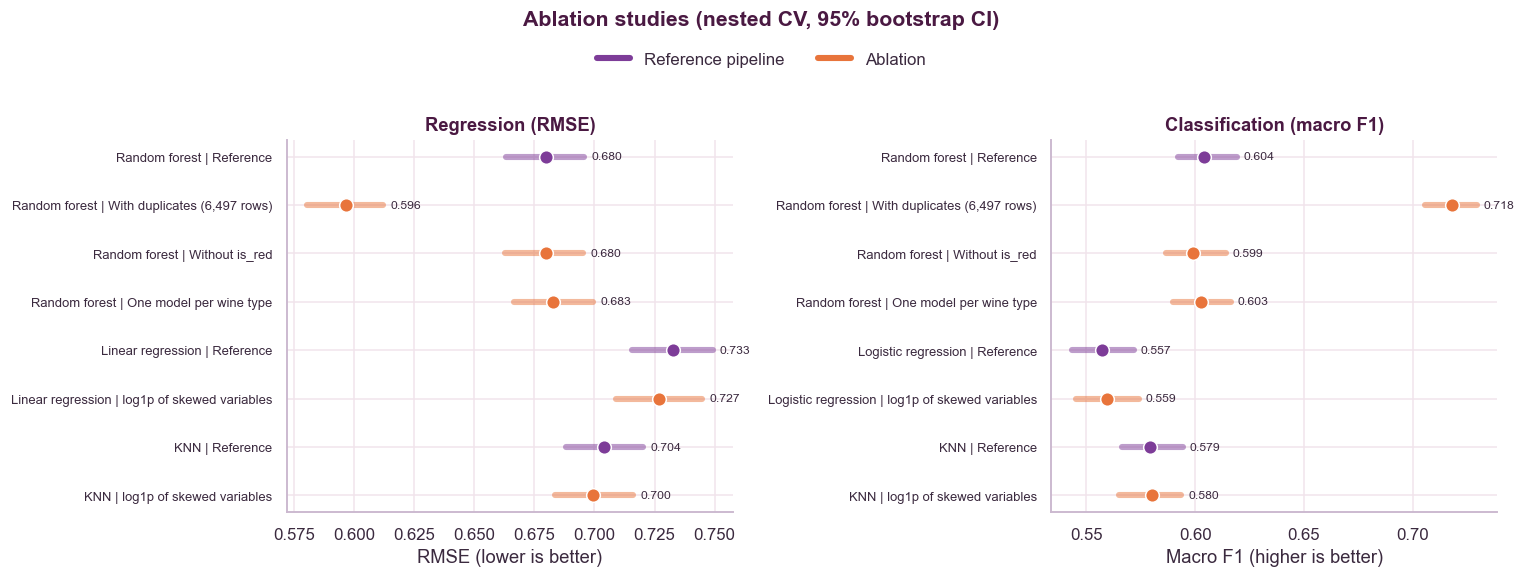

In [10]:
ablation = pd.DataFrame(rows)
ablation.to_csv(RES_DIR / "ablation_results.csv", index=False)
display(ablation.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, task, xlabel in [(axes[0], "Regression (RMSE)", "RMSE (lower is better)"),
                         (axes[1], "Classification (macro F1)", "Macro F1 (higher is better)")]:
    sub = ablation[ablation.task == task].reset_index(drop=True)
    labels = [f"{m} | {e}" for m, e in zip(sub.model, sub.experiment)]
    for i, row in sub.iloc[::-1].reset_index(drop=True).iterrows():
        color = PURPLE if row.experiment == "Reference" else ORANGE
        ax.plot([row["CI low"], row["CI high"]], [i, i], color=color, lw=4, alpha=0.5, solid_capstyle="round")
        ax.scatter(row["mean"], i, s=80, color=color, edgecolor="white", zorder=3)
        ax.text(row["CI high"] + 0.003, i, f"{row['mean']:.3f}", va="center", fontsize=8)
    ax.set_yticks(range(len(sub)), labels[::-1], fontsize=8.5)
    ax.set_xlabel(xlabel)
    ax.set_title(task)
handles = [plt.Line2D([], [], color=PURPLE, lw=4, label="Reference pipeline"),
           plt.Line2D([], [], color=ORANGE, lw=4, label="Ablation")]
fig.legend(handles=handles, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.04))
fig.suptitle("Ablation studies (nested CV, 95% bootstrap CI)", color=PLUM, weight="semibold",
             fontsize=14, y=1.09)
fig.tight_layout()
save(fig, "abl_ablation_results.png")
plt.show()

## Summary

* Keeping the duplicates makes the scores look much better, but only because many test wines
  have an identical copy in the training folds.
* The other decisions (wine type as input, one joint model, log transform) change the results
  very little. The paired bootstrap interval of the difference tells if the change is real.